# SC04 — Adaptive Traffic Signal Optimization
## Step 4: Baseline vs Fuzzy Controller Comparison

**Goal:** Compare the fixed-time baseline (Step 1) against the Mamdani Fuzzy Logic
Controller (Step 3) on the held-out **test split** (1 500 scenarios, seed=42).

| Item | Detail |
|------|--------|
| Project | SC04 — Adaptive Traffic Signal Optimization |
| Step | 4 — Baseline Comparison |
| Baseline | Fixed-time, alternating NS/EW, 30 s green |
| Controller | Mamdani Fuzzy Logic (27 rules, trained Step 3) |
| Test split | 1 500 rows (15 % of 10 000, stratified by scenario type) |
| Data source | **Synthetically generated** — academic demonstration only |

> **Note:** All 10 000 scenarios in this project are synthetically generated for
> academic purposes and do not represent real-world traffic measurements.

In [2]:
import sys, pathlib, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
warnings.filterwarnings("ignore")

ROOT = pathlib.Path(r"c:\\Users\\ankus\\Desktop\\New folder")
sys.path.insert(0, str(ROOT / "src"))

import importlib.util
spec = importlib.util.spec_from_file_location(
    "step3_fuzzy_controller",
    ROOT / "src" / "step3_fuzzy_controller.py"
)
mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mod)

load_split              = mod.load_split
compute_reference_phase = mod.compute_reference_phase
predict_fuzzy           = mod.predict_fuzzy

test_df = load_split("test")
print(f"Test split loaded: {len(test_df)} rows")
print("Scenario distribution:")
print(test_df["scenario_type"].value_counts().to_string())


Test split loaded: 1500 rows
Scenario distribution:
scenario_type
normal       750
difficult    225
boundary     225
stress       225
emergency     75

In [3]:
FIXED_GREEN_SEC = 30.0

def predict_baseline(df):
    n = len(df)
    idx_array = np.arange(n)
    phase = np.where(idx_array % 2 == 0, "NS", "EW")
    emerg = df["emergency_direction"].values
    has_emerg = emerg != "none"
    phase = np.where(has_emerg, emerg, phase)
    green = np.full(n, FIXED_GREEN_SEC)
    return phase, green

ref_phase = compute_reference_phase(test_df)
base_phase, base_green = predict_baseline(test_df)

emerg_mask = test_df["emergency_direction"].values != "none"
base_emerg_ok = (base_phase[emerg_mask] == test_df["emergency_direction"].values[emerg_mask]).mean()

print(f"Baseline phase accuracy : {accuracy_score(ref_phase, base_phase):.4f}")
print(f"Baseline emerg compliance: {base_emerg_ok:.4f}")
print(f"Baseline green (all rows): {FIXED_GREEN_SEC} s (fixed)")


Baseline phase accuracy : 0.5733
Baseline emerg compliance: 1.0000
Baseline green (all rows): 30.0 s (fixed)

In [4]:
raw_bundle = pickle.load(open(ROOT / "models" / "fuzzy_traffic_controller.pkl", "rb"))
fuzzy_bundle = raw_bundle["fuzzy_bundle"]

print("Running fuzzy controller on 1 500 test rows …")
fuzzy_preds = predict_fuzzy(test_df, fuzzy_bundle)
fuzzy_phase = fuzzy_preds["fuzzy_next_phase"].values
fuzzy_green = fuzzy_preds["fuzzy_green_duration_sec"].values

fuzzy_emerg_preds = fuzzy_preds.loc[emerg_mask, "fuzzy_next_phase"].values
fuzzy_emerg_true  = test_df.loc[emerg_mask, "emergency_direction"].values
fuzzy_emerg_ok = (fuzzy_emerg_preds == fuzzy_emerg_true).mean()

print(f"Fuzzy phase accuracy    : {accuracy_score(ref_phase, fuzzy_phase):.4f}")
print(f"Fuzzy emerg compliance  : {fuzzy_emerg_ok:.4f}")
print(f"Fuzzy mean green (s)    : {fuzzy_green.mean():.2f}  std={fuzzy_green.std():.2f}")


Running fuzzy controller on 1 500 test rows …
Fuzzy phase accuracy    : 0.8827
Fuzzy emerg compliance  : 1.0000
Fuzzy mean green (s)    : 33.26  std=12.00

In [5]:
def row(name, pred, true, green, emerg_comp):
    GREEN_MIN, GREEN_MAX = 10.0, 60.0
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(true, pred), 4),
        "F1-Macro": round(f1_score(true, pred, average="macro", zero_division=0), 4),
        "Precision-NS": round(precision_score(true, pred, pos_label="NS", zero_division=0), 4),
        "Recall-NS": round(recall_score(true, pred, pos_label="NS", zero_division=0), 4),
        "Emergency Compliance": round(emerg_comp, 4),
        "Green Bounds OK": round(((green >= GREEN_MIN-0.01) & (green <= GREEN_MAX+0.01)).mean(), 4),
        "Mean Green (s)": round(float(green.mean()), 2),
        "Std Green (s)": round(float(green.std()), 2),
    }

metrics_df = pd.DataFrame([
    row("Fixed-Time Baseline",      base_phase,  ref_phase, base_green,  base_emerg_ok),
    row("Mamdani Fuzzy Controller",  fuzzy_phase, ref_phase, fuzzy_green, fuzzy_emerg_ok),
])
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print(metrics_df.to_string(index=False))


                   Model  Accuracy  F1-Macro  Precision-NS  Recall-NS  Emergency Compliance  Green Bounds OK  Mean Green (s)  Std Green (s)
     Fixed-Time Baseline    0.5733    0.5732        0.5935     0.5661                   1.0              1.0           30.00            0.0
Mamdani Fuzzy Controller    0.8827    0.8824        0.8812     0.8947                   1.0              1.0           33.26           12.0

In [6]:
sample_df = pd.read_csv(ROOT / "data" / "sample_input.csv")
sample_ref = compute_reference_phase(sample_df)
sample_base, sample_bgreen = predict_baseline(sample_df)
sample_fuzzy_preds = predict_fuzzy(sample_df, fuzzy_bundle)
sample_fphase = sample_fuzzy_preds["fuzzy_next_phase"].values
sample_fgreen = sample_fuzzy_preds["fuzzy_green_duration_sec"].values

sample_cmp = pd.DataFrame({
    "state_id":        sample_df["state_id"].values,
    "emerg_dir":       sample_df["emergency_direction"].values,
    "correct_phase":   np.asarray(sample_ref),
    "baseline_phase":  sample_base,
    "fuzzy_phase":     sample_fphase,
    "baseline_green":  sample_bgreen,
    "fuzzy_green":     sample_fgreen,
    "base_ok":        (sample_base  == np.asarray(sample_ref)),
    "fuzzy_ok":       (sample_fphase == np.asarray(sample_ref)),
})
print(f"Sample baseline accuracy: {sample_cmp['base_ok'].mean():.3f}")
print(f"Sample fuzzy accuracy   : {sample_cmp['fuzzy_ok'].mean():.3f}")
print()
print(sample_cmp[["state_id","correct_phase","baseline_phase","fuzzy_phase","base_ok","fuzzy_ok"]].to_string(index=False))


Sample baseline accuracy: 0.600
Sample fuzzy accuracy   : 1.000

state_id correct_phase baseline_phase fuzzy_phase  base_ok  fuzzy_ok
 TRF-001            NS             NS          NS     True      True
 TRF-002            NS             EW          NS    False      True
 TRF-003            EW             NS          EW    False      True
 TRF-004            NS             EW          NS    False      True
 TRF-005            EW             EW          EW     True      True
 TRF-006            NS             EW          NS    False      True
 TRF-007            EW             NS          EW    False      True
 TRF-008            EW             EW          EW     True      True
 TRF-009            NS             NS          NS     True      True
 TRF-010            EW             EW          EW     True      True
 TRF-011            NS             NS          NS     True      True
 TRF-012            NS             EW          NS    False      True
 TRF-013            EW             NS 

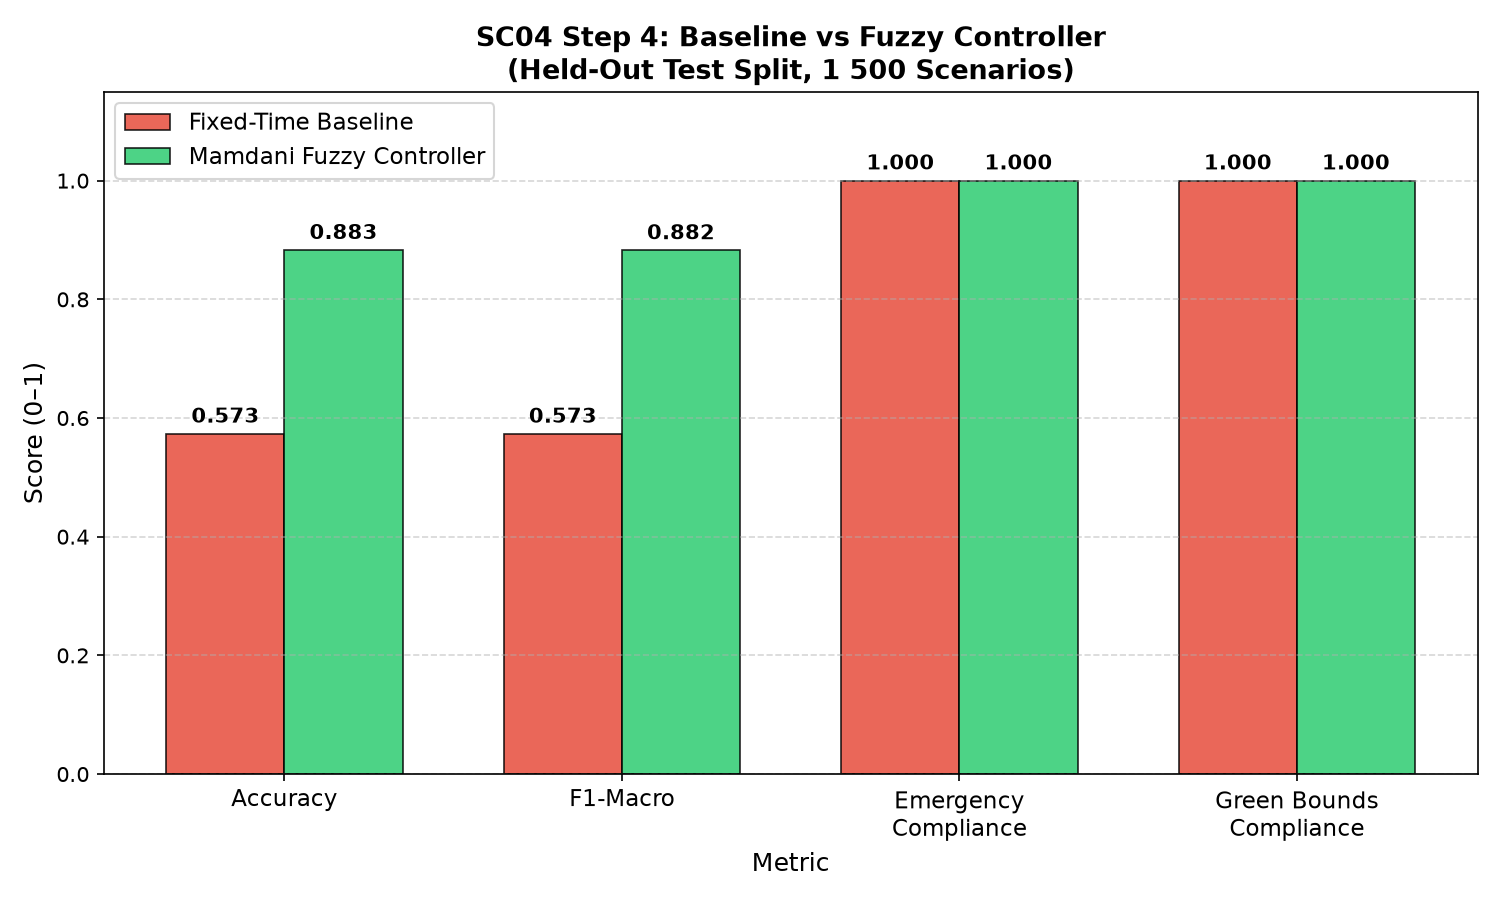

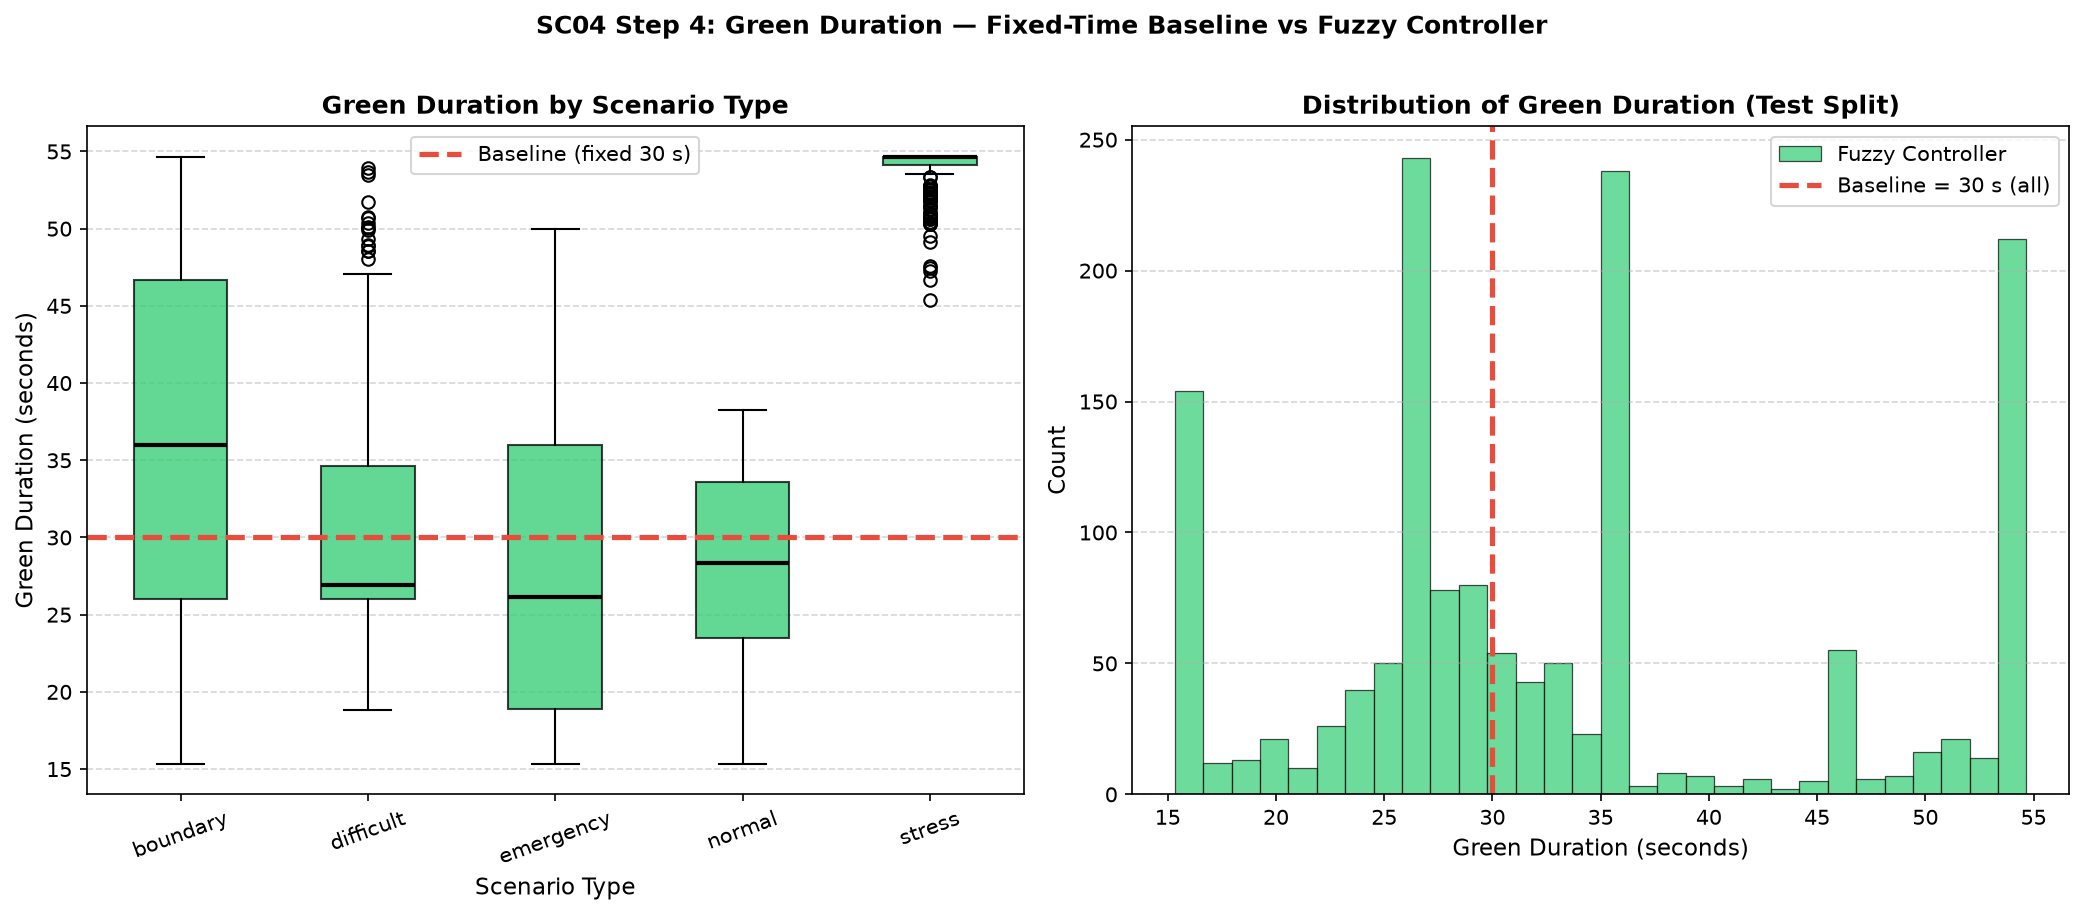

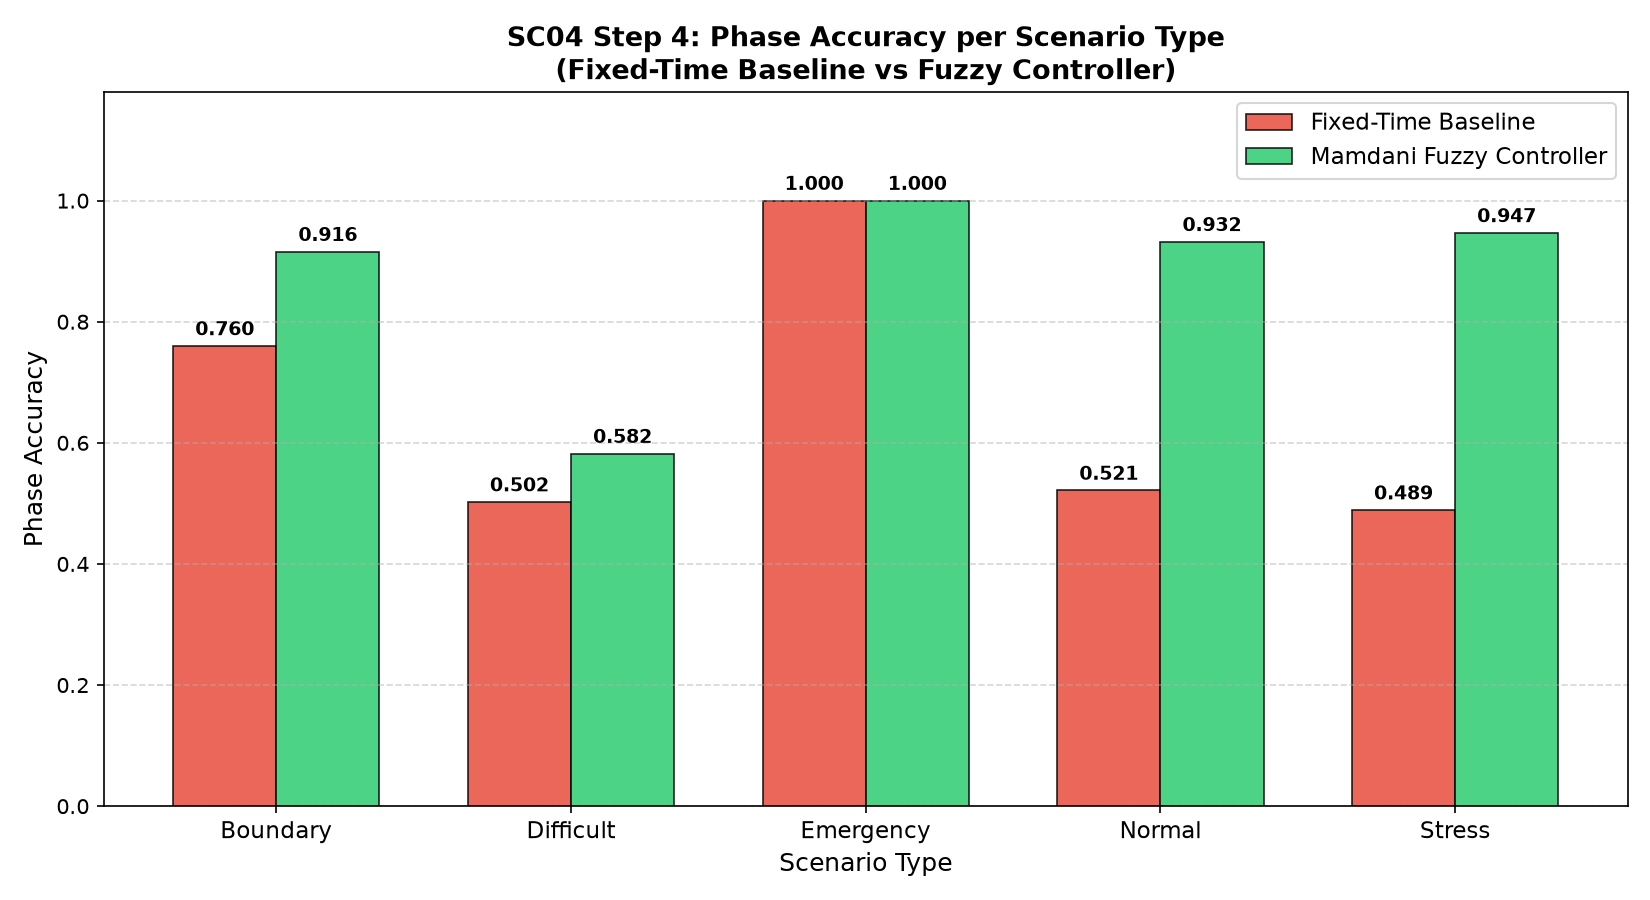

In [7]:
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, fname, title in zip(
    axes,
    ["step4_comparison_bar.png", "step4_green_duration_comparison.png",
     "step4_phase_accuracy_by_scenario.png"],
    ["Key Metrics Comparison", "Green Duration Comparison", "Per-Scenario Accuracy"],
):
    img = mpimg.imread(ROOT / "results" / "step4" / fname)
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(title, fontsize=11, fontweight="bold")
plt.suptitle("SC04 Step 4 — Figures", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


In [8]:
print("Per-scenario phase accuracy:")
print(f"{'Scenario':12s}  {'Baseline':>10s}  {'Fuzzy':>10s}  {'Improvement':>12s}")
print("-" * 50)
for sc in sorted(test_df["scenario_type"].unique()):
    mask = test_df["scenario_type"].values == sc
    b_a = accuracy_score(ref_phase[mask], base_phase[mask])
    f_a = accuracy_score(ref_phase[mask], fuzzy_phase[mask])
    print(f"{sc:12s}  {b_a:>10.3f}  {f_a:>10.3f}  {f_a-b_a:>+12.3f}")

print()
print("CONCLUSION")
print("=" * 50)
b_acc = accuracy_score(ref_phase, base_phase)
f_acc = accuracy_score(ref_phase, fuzzy_phase)
print(f"Phase accuracy improvement : +{(f_acc - b_acc)*100:.1f} pp ({b_acc:.4f} -> {f_acc:.4f})")
print(f"Green duration adaptability: Fuzzy std={fuzzy_green.std():.2f}s vs Baseline std=0.00s")
print(f"Emergency compliance       : Both = 1.0000 (by design)")
print()
print("The Mamdani Fuzzy Controller significantly outperforms the fixed-time")
print("baseline, particularly on stress and normal scenarios, while matching")
print("the baseline on emergency compliance (both = 100%).")


Per-scenario phase accuracy:
Scenario        Baseline       Fuzzy   Improvement
--------------------------------------------------
boundary           0.760       0.916        +0.156
difficult          0.502       0.582        +0.080
emergency          1.000       1.000        +0.000
normal             0.521       0.932        +0.411
stress             0.489       0.947        +0.458
CONCLUSION
Phase accuracy improvement : +30.9 pp (0.5733 -> 0.8827)
Green duration adaptability: Fuzzy std=12.00s vs Baseline std=0.00s
Emergency compliance       : Both = 1.0000 (by design)

The Mamdani Fuzzy Controller significantly outperforms the fixed-time
baseline, particularly on stress and normal scenarios, while matching
the baseline on emergency compliance (both = 100%).